<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/07_seven_assets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 - Seven assets: stocks, gold, bonds

S&P 500, Apple, Microsoft, JPMorgan, ExxonMobil, gold (GLD) and 20+ year US Treasuries (TLT). GLD only starts in November 2004, so everything here runs from 2004-11 and the backtest from 2008-11 (after the 1000-day window): most of the 2008 crash is not in it. Data from yfinance, adjusted for splits and dividends.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk import *

assets = ["spx", "aapl", "msft", "jpm", "xom", "gld", "tlt"]
prices = pd.concat({a: load_close("../black-scholes-sp500/data/sp500.csv" if a == "spx" else f"data/{a}.csv") for a in assets},
                   axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1
print(len(rets), "days", rets.index[0].date(), "->", rets.index[-1].date())
print("annual vol:", (rets.std() * np.sqrt(252)).round(3).to_dict())

5535 days 2004-11-19 -> 2026-11-19
annual vol: {'spx': 0.19, 'aapl': 0.32, 'msft': 0.273, 'jpm': 0.352, 'xom': 0.265, 'gld': 0.184, 'tlt': 0.145}


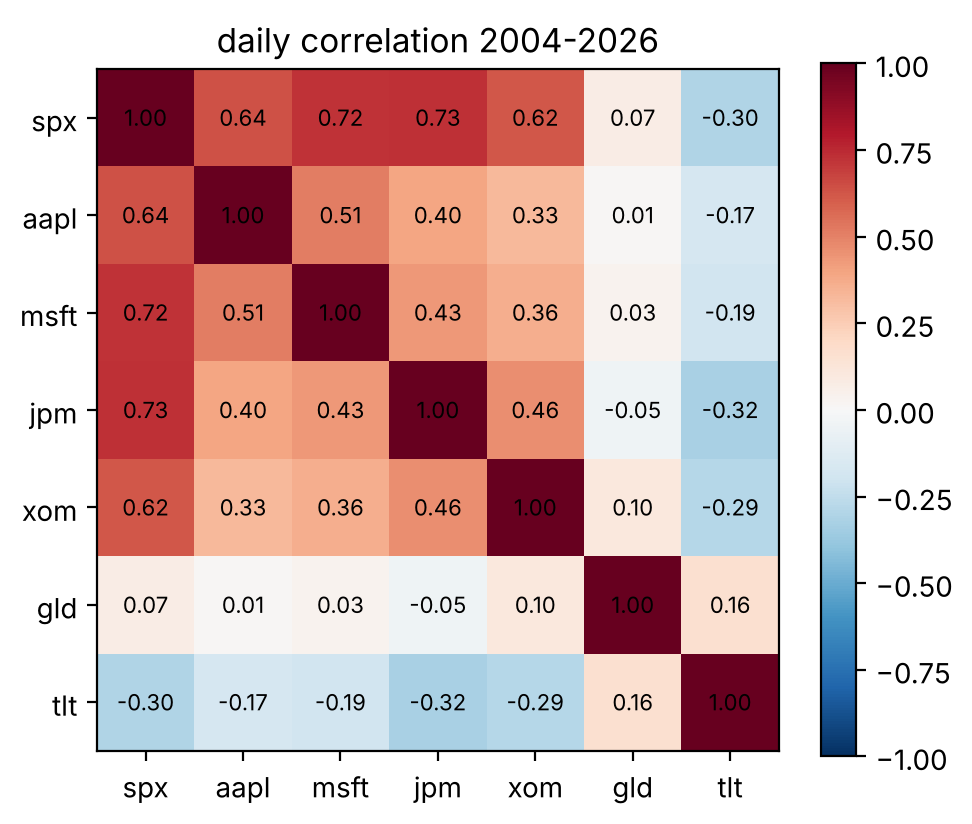

mean return (%) on the 5% worst S&P days: {'spx': -2.98, 'aapl': -3.16, 'msft': -2.98, 'jpm': -4.12, 'xom': -2.58, 'gld': -0.06, 'tlt': 0.82}


In [3]:
corr = rets.corr()
plt.figure(figsize=(5.5, 4.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(7), assets); plt.yticks(range(7), assets)
for i in range(7):
    for j in range(7):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(); plt.title("daily correlation 2004-2026"); plt.show()

bad = rets.spx < rets.spx.quantile(0.05)
print("mean return (%) on the 5% worst S&P days:", (100 * rets[bad].mean()).round(2).to_dict())
# the 5 stocks: 0.33-0.73 with each other. gold ~0 with everything, bonds negative with all stocks
# on the worst S&P days the stocks lose 2.6-4.1% (JPM the most), gold ~0 and bonds gain 0.8%

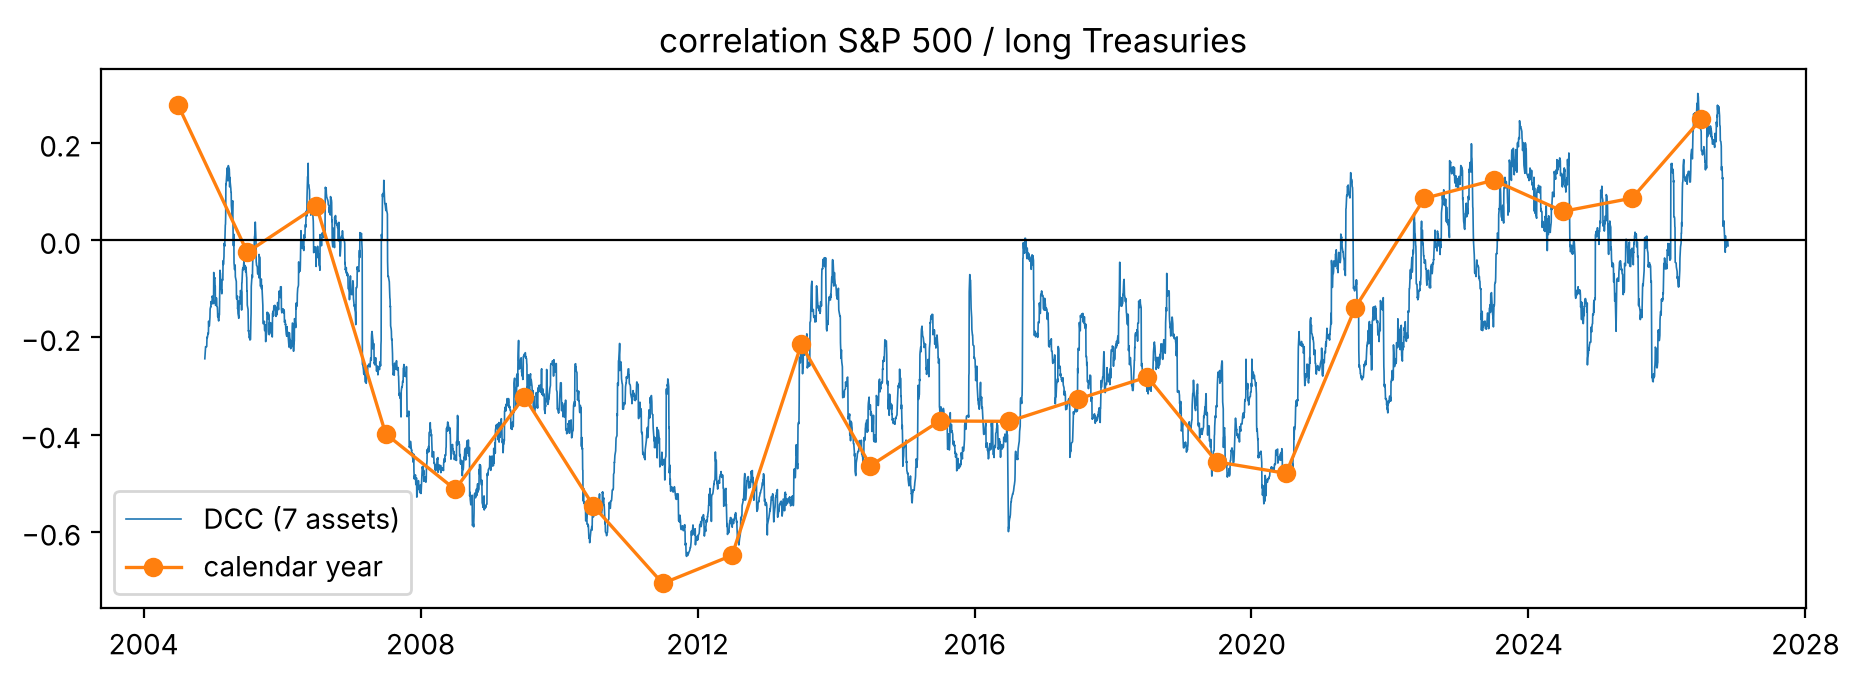

dcc a 0.0179  b 0.9751
by year: {2004: 0.28, 2005: -0.02, 2006: 0.07, 2007: -0.4, 2008: -0.51, 2009: -0.32, 2010: -0.55, 2011: -0.71, 2012: -0.65, 2013: -0.21, 2014: -0.46, 2015: -0.37, 2016: -0.37, 2017: -0.33, 2018: -0.28, 2019: -0.46, 2020: -0.48, 2021: -0.14, 2022: 0.09, 2023: 0.12, 2024: 0.06, 2025: 0.09, 2026: 0.25}


In [4]:
X = rets.values - rets.values.mean(axis=0)
Z = np.column_stack([X[:, i] / np.sqrt(garch_filter(X[:, i], *garch_fit(rets.values[:, i]))[:-1]) for i in range(7)])
a_dcc, b_dcc = dcc_fit(Z)
dcc_sb = pd.Series(dcc_filter(Z, a_dcc, b_dcc)[:-1, 0, 6], index=rets.index)
yearly = rets.groupby(rets.index.year).apply(lambda g: g.spx.corr(g.tlt))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(dcc_sb, lw=0.6, label="DCC (7 assets)")
ax.plot(pd.to_datetime([f"{y}-07-01" for y in yearly.index]), yearly.values, "o-", lw=1.2, label="calendar year")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("correlation S&P 500 / long Treasuries"); ax.legend(); plt.show()
print("dcc a", round(a_dcc, 4), " b", round(b_dcc, 4))
print("by year:", yearly.round(2).to_dict())
# negative from 2007 to 2021 (down to -0.71 in 2011): bonds went up when stocks fell
# from 2022 it is positive (+0.06 to +0.25): with inflation, stocks and bonds fell together in 2022
# so the hedge that bonds gave for 15 years is mostly gone since 2022

In [5]:
w_eq = np.full(7, 1 / 7)
w_rb = equal_risk_weights(simple.values)
print("share of the ES with 1/7 each:", dict(zip(assets, es_contributions(simple.values, w_eq).round(3))))
print("equal-risk weights:           ", dict(zip(assets, w_rb.round(3))))
print("check, share of the ES:       ", es_contributions(simple.values, w_rb).round(3))
print()
for nm, ww in [("1/7", w_eq), ("equal risk", w_rb), ("S&P 500 alone", np.eye(7)[0])]:
    p = np.log1p(simple.values @ ww)
    v, e = var_es_hist(p)
    print(f"{nm:14s} return {252 * p.mean():5.1%}  vol {np.sqrt(252) * p.std():5.1%}  VaR {v:.2%}  ES {e:.2%}")
# with 1/7 each, JPM brings 28% of the ES and the bonds reduce it (-3.4%)
# equal risk puts 44.5% in bonds, 17% in gold and 6.5-8% in each stock: ES 3.90% -> 2.13%, but return 14.1% -> 10.2%
# weights computed on the whole period (look-ahead), and mostly on 2004-2021 when bonds still hedged

share of the ES with 1/7 each: {'spx': np.float64(0.182), 'aapl': np.float64(0.192), 'msft': np.float64(0.18), 'jpm': np.float64(0.281), 'xom': np.float64(0.19), 'gld': np.float64(0.009), 'tlt': np.float64(-0.034)}
equal-risk weights:            {'spx': np.float64(0.083), 'aapl': np.float64(0.078), 'msft': np.float64(0.08), 'jpm': np.float64(0.065), 'xom': np.float64(0.078), 'gld': np.float64(0.172), 'tlt': np.float64(0.445)}
check, share of the ES:        [0.143 0.14  0.142 0.144 0.142 0.143 0.146]

1/7            return 14.1%  vol 15.3%  VaR 2.68%  ES 3.90%
equal risk     return 10.2%  vol  9.6%  VaR 1.58%  ES 2.13%
S&P 500 alone  return  8.2%  vol 19.0%  VaR 3.52%  ES 5.24%


In [6]:
port = np.log1p(simple @ w_eq)   # backtest on 1/7, no look-ahead in the weights
bt = pd.concat([backtest(port), portfolio_backtest(rets, w_eq).drop(columns="ret")], axis=1)
names = {"normal": "normal", "hist": "historical", "garch": "garch", "gt": "garch student-t", "skt": "garch skewed-t",
         "gjrskt": "GJR skewed-t", "fhs": "FHS", "evt": "garch-EVT", "ewma": "EWMA", "mfhs": "multivariate FHS", "dcc": "DCC-FHS"}
print(len(bt), "days from", bt.index[0].date(), ", expected", round(0.01 * len(bt)), "breaches")
for m in names:
    breach = bt["ret"] < -bt[f"var_{m}"]
    ratio = (-bt["ret"][breach]).mean() / bt[f"es_{m}"][breach].mean()
    print(f"{names[m]:17s} {breach.sum():3d} ({100*breach.mean():.2f}%)  kupiec p={kupiec(breach.values)[1]:.3f}  "
          f"christoffersen p={christoffersen(breach.values)[1]:.3f}  loss/ES={ratio:.2f}  2020: {breach.loc['2020'].sum()}")
# normal, garch and EWMA: 1.65-1.84%, rejected. the others are at 1.0-1.3%
# but most of them have their breaches in clusters (christoffersen < 5%), mainly march 2020
# only GJR skewed-t (0.95%), FHS and garch-EVT pass both. DCC gets the rate (1.04%) but not the clustering

4535 days from 2008-11-10 , expected 45 breaches
normal             75 (1.65%)  kupiec p=0.000  christoffersen p=0.000  loss/ES=1.36  2020: 20
historical         48 (1.06%)  kupiec p=0.695  christoffersen p=0.000  loss/ES=1.02  2020: 15
garch              76 (1.68%)  kupiec p=0.000  christoffersen p=0.048  loss/ES=1.15  2020: 11
garch student-t    57 (1.26%)  kupiec p=0.095  christoffersen p=0.040  loss/ES=1.02  2020: 9
garch skewed-t     51 (1.12%)  kupiec p=0.408  christoffersen p=0.021  loss/ES=1.01  2020: 8
GJR skewed-t       43 (0.95%)  kupiec p=0.723  christoffersen p=0.069  loss/ES=1.05  2020: 6
FHS                49 (1.08%)  kupiec p=0.591  christoffersen p=0.116  loss/ES=0.98  2020: 9
garch-EVT          46 (1.01%)  kupiec p=0.923  christoffersen p=0.091  loss/ES=1.00  2020: 9
EWMA               83 (1.83%)  kupiec p=0.000  christoffersen p=0.022  loss/ES=1.17  2020: 11
multivariate FHS   45 (0.99%)  kupiec p=0.958  christoffersen p=0.010  loss/ES=1.00  2020: 8
DCC-FHS          

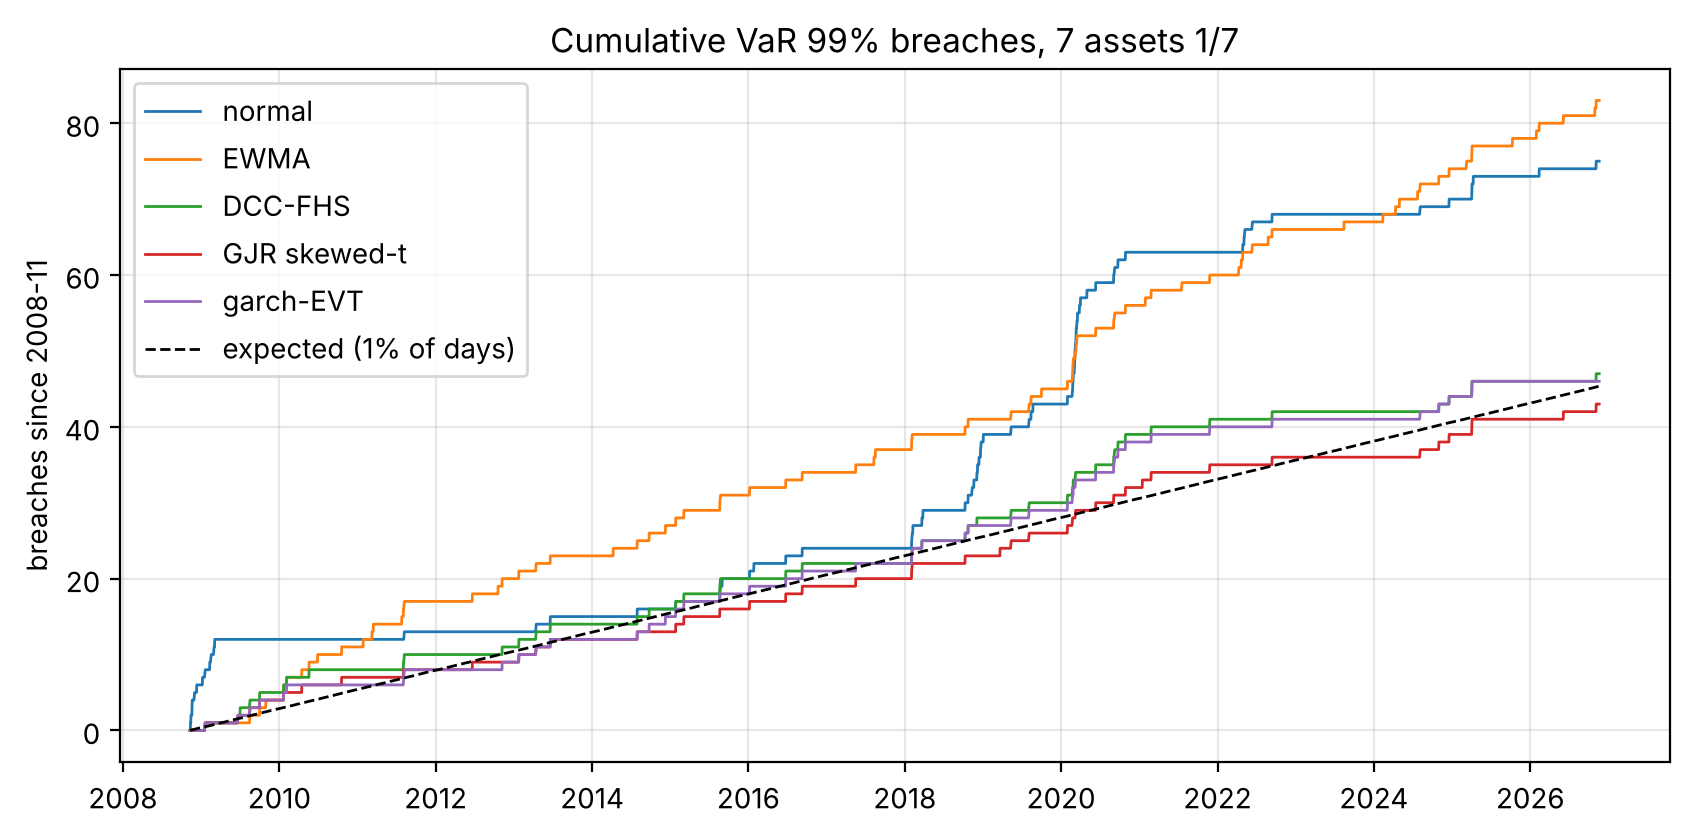

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for m in ["normal", "ewma", "dcc", "gjrskt", "evt"]:
    ax.plot((bt["ret"] < -bt[f"var_{m}"]).cumsum(), lw=1, label=names[m])
ax.plot(bt.index, 0.01 * np.arange(1, len(bt) + 1), "k--", lw=1, label="expected (1% of days)")
ax.set_ylabel("breaches since 2008-11"); ax.set_title("Cumulative VaR 99% breaches, 7 assets 1/7")
ax.grid(alpha=0.3); ax.legend(); plt.show()
# every model jumps in march 2020. the normal one also at the start (end of the 2008 crisis), in 2018 and 2022
# EWMA has no big jump but rises too fast all the time. the good ones barely move in 2022, when stocks and bonds fell together